# Assignment 3 - Sampling Distributions and Estimation

Group members: Sebastian Bartko, Mariia Moskovko, Matej Palas, Sebastian Halas, ...

Table of contents
1. Part I - Sampling distributions and the CLT
2. Part II - Estimating mean sensor error
3. Part III - Estimating a false-rejection proportion
4. Part IV - AI-use and conclusion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.stats.proportion import proportion_confint

In [2]:
sensors = pd.read_csv("data/assignment03_sensor_calibration.csv")
access = pd.read_csv("data/assignment03_access_control.csv")

display(sensors.head())
display(access.head())

,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615


,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


# Part I Sampling distributions and the CLT

Restoration time is exponential with mean = SD = 60 minutes. We use seed 2026 and 20,000 repetitions for each sample size.

In [3]:
mu = sigma = 60
reps = 20_000
sizes = [1, 5, 20, 80]
rng = np.random.default_rng(2026)

means = {}
for n in sizes:
    samples = rng.exponential(scale=mu, size=(reps, n))
    means[n] = samples.mean(axis=1)

rows = []
for n in sizes:
    rows.append({
        "n": n,
        "theoretical mean": mu,
        "simulated mean of means": means[n].mean(),
        "theoretical SE": sigma / np.sqrt(n),
        "empirical SD of means": means[n].std(ddof=1),
    })
pd.DataFrame(rows)

,n,theoretical mean,simulated mean of means,theoretical SE,empirical SD of means
0,1,60,60.327869,60.000000,60.199020
1,5,60,59.500194,26.832816,26.683556
2,20,60,59.936719,13.416408,13.352604
3,80,60,59.990481,6.708204,6.739603


**a. Table**

The mean of the sample means is close to 60 for every n, so the sample mean is centred at the population mean. The SD of the sample means matches the theoretical SE (σ/√n). When n gets 4 times bigger (5 to 20, 20 to 80), the SE is cut in half.

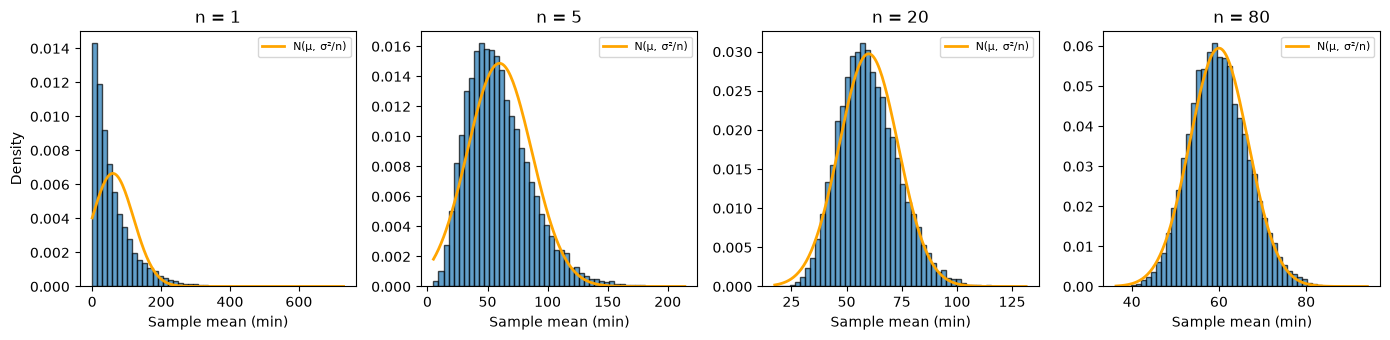

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, n in zip(axes, sizes):
    se = sigma / np.sqrt(n)
    ax.hist(means[n], bins=50, density=True, edgecolor="black", alpha=0.7)
    x = np.linspace(means[n].min(), means[n].max(), 200)
    ax.plot(x, norm.pdf(x, mu, se), color="orange", lw=2, label="N(μ, σ²/n)")
    ax.set(title=f"n = {n}", xlabel="Sample mean (min)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

**b. Sampling distributions**

- Centre: all four histograms are centred around 60.
- Spread: they get narrower as n grows, since the SE is σ/√n.
- Shape: for n = 1 it is just the exponential distribution, very skewed to the right, and the normal curve fits badly (it even goes below 0). For n = 5 it is still skewed, for n = 20 a bit less, and for n = 80 it looks almost normal.

The normal curve is only an approximation here because the population itself is not normal. If the population was normal, the sample mean would be exactly normal for any n. Here the CLT only says it gets closer to normal as n grows, but some skew is always left.

In [5]:
for n in [20, 80]:
    sim = np.mean(means[n] > 75)
    clt = norm.sf(75, loc=mu, scale=sigma / np.sqrt(n))
    print(f"n = {n}: simulated P(X̄ > 75) = {sim:.4f}, CLT approximation = {clt:.4f}")

n = 20: simulated P(X̄ > 75) = 0.1334, CLT approximation = 0.1318
n = 80: simulated P(X̄ > 75) = 0.0186, CLT approximation = 0.0127


**c. P(X̄ > 75)**

For n = 20 the simulation and the CLT give almost the same answer (0.133 vs 0.132). For n = 80 the simulation gives 0.019 and the CLT 0.013. The numbers are small, but the CLT is about 30% too low. 75 is far out in the right tail for n = 80, and the sample means are still a bit right-skewed, so the real tail is heavier than the normal curve. The CLT works well in the middle, but in the far tails it is less accurate.

**d. Smallest n with SE ≤ 6**

60/√n ≤ 6, so √n ≥ 10, so n ≥ 100.

In [6]:
n_min = int(np.ceil((sigma / 6) ** 2))
print(f"Smallest n: {n_min}")

for n in [n_min - 1, n_min]:
    sim_means = rng.exponential(scale=mu, size=(reps, n)).mean(axis=1)
    print(f"n = {n}: theoretical SE = {sigma / np.sqrt(n):.3f}, simulated SD of means = {sim_means.std(ddof=1):.3f}")

Smallest n: 100
n = 99: theoretical SE = 6.030, simulated SD of means = 6.080
n = 100: theoretical SE = 6.000, simulated SD of means = 6.019


So n = 100 is the smallest sample size (SE is exactly 6). With n = 99 the SE is just over 6. The simulated values are close to the theoretical ones, the small differences are just random noise.

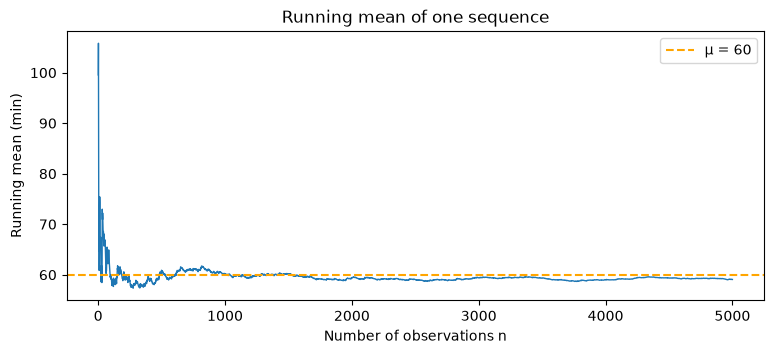

In [7]:
n_lln = 5_000
sequence = rng.exponential(scale=mu, size=n_lln)
running_mean = np.cumsum(sequence) / np.arange(1, n_lln + 1)

plt.figure(figsize=(9, 3.5))
plt.plot(np.arange(1, n_lln + 1), running_mean, lw=1)
plt.axhline(mu, color="orange", linestyle="--", label="μ = 60")
plt.xlabel("Number of observations n")
plt.ylabel("Running mean (min)")
plt.title("Running mean of one sequence")
plt.legend()
plt.show()

**e. Law of large numbers**

The running mean jumps around a lot at the start and then settles close to 60 as more observations are added. That is the law of large numbers: the more observations in one sample, the closer the sample mean gets to the population mean.

This is not a sampling distribution. Here we follow one sample that keeps growing. A sampling distribution uses many separate samples of the same size n and shows how much the mean varies between them. The LLN only says the mean gets close to 60, it does not say anything about the shape. The shape is what the CLT is about.

**f. What the CLT does not do**

The CLT is only about sample means. It does not make single restoration times normal, one restoration time is still exponential and skewed. It also assumes independent observations from the same population, so it does not help if:
- observations depend on each other (e.g. several outages from the same incident)
- the times change over time (e.g. slower repairs in a busy period)
- the sample is not representative (e.g. only daytime repairs)

# Part II Estimating mean sensor error

The file `assignment03_sensor_calibration.csv` contains calibration errors from 64 independently selected temperature sensors. Error is `sensor reading − reference temperature`. Let $\mu$ be the population mean calibration error.

Complete the following tasks:

**a. Report $n$, $\bar{x}$, $s$, and the estimated standard error. Explain standard deviation versus standard error.**

In [8]:
df = pd.read_csv("data/assignment03_sensor_calibration.csv")
x = df["calibration_error_c"].to_numpy()

n = len(x)
x_bar = x.mean()
s = x.std(ddof=1)  # sample SD, divides by n - 1
se = s / np.sqrt(n)

print(f"n      = {n}")
print(f"mean   = {x_bar:.4f} C")
print(f"sd     = {s:.4f} C")
print(f"SE     = sd / sqrt(n) = {s:.4f} / sqrt({n}) = {se:.4f}")

n      = 64
mean   = 0.1883 C
sd     = 0.6257 C
SE     = sd / sqrt(n) = 0.6257 / sqrt(64) = 0.0782


- The **standard deviation** $s$ describes the spread of the *individual sensors*. A typical sensor's error is about 0.6257 °C away from the average error. It is a property of the data: collecting more sensors would not make it shrink, it would only be estimated more precisely.
- The **standard error** $s/\sqrt{n}$ describes the spread of the *sample mean* $\bar{x}$. If we repeated the study many times with 64 new sensors, the sample means would vary around $\mu$ by 0.0782 °C. It measures how precisely $\bar{x}$ estimates $\mu$, and it gets smaller as $n$ grows (4 times as many sensors halves it).

**b. Create a histogram and normal QQ-plot. Discuss whether a one-sample $t$ interval appears reasonable and why plots cannot establish independence.**

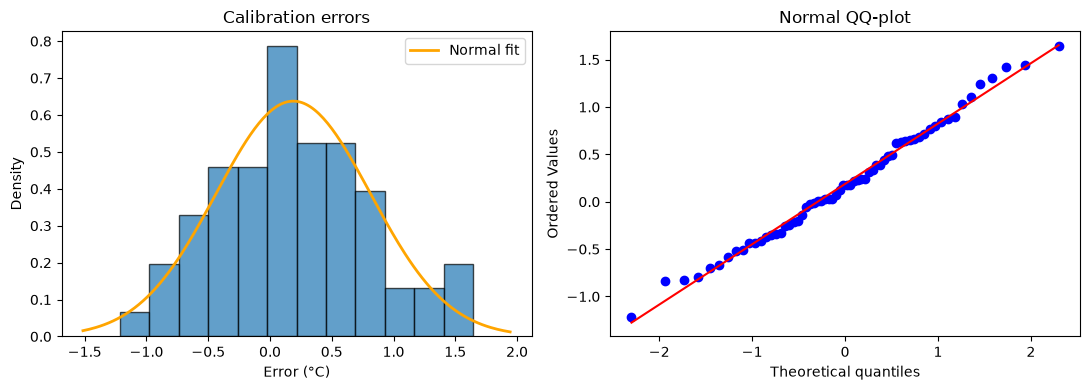

In [9]:
from scipy.stats import probplot, skew

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(x, bins=12, density=True, edgecolor="black", alpha=0.7)
grid = np.linspace(x.min() - 0.3, x.max() + 0.3, 200)
axes[0].plot(grid, norm.pdf(grid, x_bar, s), color="orange", lw=2, label="Normal fit")
axes[0].set(title="Calibration errors", xlabel="Error (°C)", ylabel="Density")
axes[0].legend()

probplot(x, dist="norm", plot=axes[1])
axes[1].set_title("Normal QQ-plot")

plt.tight_layout()
plt.show()


A one-sample $t$ interval looks reasonable. The data are close to normal with a  small skew to the right.

The plots cannot establish independence because they only show the *distribution* of the values, not how the sensors were selected or related to each other.

**c. Construct a 95% $t$ interval by calculating the degrees of freedom, critical value, standard error, and margin of error. Verify it with SciPy and interpret both the interval and the 95% confidence level correctly.**

In [10]:
from scipy.stats import t

conf = 0.95
dof = n - 1
t_crit = t.ppf(1 - (1 - conf) / 2, dof)
moe = t_crit * se
lower, upper = x_bar - moe, x_bar + moe

print(f"df             = n - 1 = {dof}")
print(f"t critical     = {t_crit:.4f}")
print(f"SE             = {se:.4f}")
print(f"margin (ME)    = t* x SE = {t_crit:.4f} x {se:.4f} = {moe:.4f}")
print(f"95% CI (hand)  = [{lower:.4f}, {upper:.4f}] C")

ci_scipy = t.interval(conf, dof, loc=x_bar, scale=se)
print(f"95% CI (SciPy) = [{ci_scipy[0]:.4f}, {ci_scipy[1]:.4f}] C")


df             = n - 1 = 63
t critical     = 1.9983
SE             = 0.0782
margin (ME)    = t* x SE = 1.9983 x 0.0782 = 0.1563
95% CI (hand)  = [0.0320, 0.3446] C
95% CI (SciPy) = [0.0320, 0.3446] C


- **Interval:** we are 95% confident that the population mean calibration error $\mu$ is between 0.032 and 0.345 °C. The whole interval is above 0, so on average the sensors seem to read slightly too high.
- **95% confidence level:** If we repeated the study many times with 64 new sensors each time and constructed an interval for each study, about 95% of those intervals would contain the true $\mu$. We do not know whether the interval we calculated is among the 95% that contain $\mu$ or the 5% that do not.

**d. Create a table of 90%, 95%, and 99% $t$ intervals and widths. Explain the confidence–precision trade-off.**

In [11]:
rows = []
for c in [0.90, 0.95, 0.99]:
    tc = t.ppf(1 - (1 - c) / 2, dof)
    me = tc * se
    rows.append({
        "confidence": f"{c:.0%}",
        "t*": round(tc, 4),
        "margin of error": round(me, 4),
        "lower": round(x_bar - me, 4),
        "upper": round(x_bar + me, 4),
        "width": round(2 * me, 4),
    })
pd.DataFrame(rows)


,confidence,t*,margin of error,lower,upper,width
0,90%,1.6694,0.1306,0.0577,0.3188,0.2612
1,95%,1.9983,0.1563,0.0320,0.3446,0.3126
2,99%,2.6561,0.2078,-0.0195,0.3960,0.4155


- Higher level (99%): catches μ more often, but the interval is wider and less precise.
- Lower level (90%): the interval is narrower, but it misses μ more often.

**e. Using $s$ as a planning value and the normal critical value, find the smallest approximate sample size for a 95% margin of error no larger than $0.10^\circ\mathrm{C}$.**

In [12]:
target_me = 0.10
z_crit = norm.ppf(0.975)
n_exact = (z_crit * s / target_me) ** 2
n_needed = int(np.ceil(n_exact))

print(f"z (95%)      = {z_crit:.4f}")
print(f"n >= (z*s/E)^2 = ({z_crit:.4f}*{s:.4f}/{target_me:.2f})^2 = {n_exact:.2f}")
print(f"round up -> n = {n_needed}")
for m in [n_needed - 1, n_needed]:
    print(f"n = {m}: margin of error = {z_crit * s / np.sqrt(m):.4f} C")


z (95%)      = 1.9600
n >= (z*s/E)^2 = (1.9600*0.6257/0.10)^2 = 150.42
round up -> n = 151
n = 150: margin of error = 0.1001 C
n = 151: margin of error = 0.0998 C


**f. With seed 2026 and at least 10,000 resamples, construct a percentile bootstrap interval. Compare it with the $t$ interval and state what the comparison cannot validate.**

bootstrap SE       = 0.0768   (t SE = 0.0782)
95% bootstrap CI   = [0.0408, 0.3413] C, width = 0.3005
95% t CI           = [0.0320, 0.3446] C, width = 0.3126


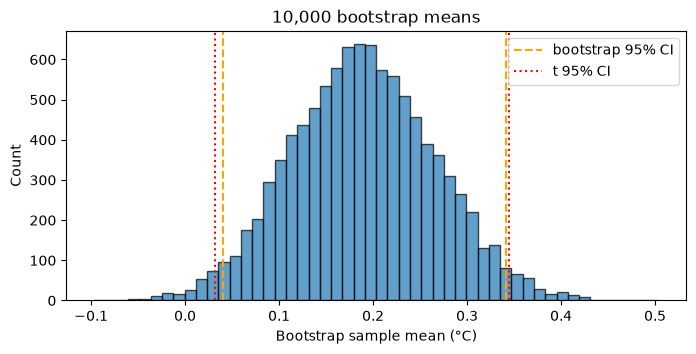

In [13]:
B = 10_000
rng_boot = np.random.default_rng(2026)
boot_means = rng_boot.choice(x, size=(B, n), replace=True).mean(axis=1)
boot_lower, boot_upper = np.percentile(boot_means, [2.5, 97.5])

print(f"bootstrap SE       = {boot_means.std(ddof=1):.4f}   (t SE = {se:.4f})")
print(f"95% bootstrap CI   = [{boot_lower:.4f}, {boot_upper:.4f}] C, width = {boot_upper - boot_lower:.4f}")
print(f"95% t CI           = [{lower:.4f}, {upper:.4f}] C, width = {upper - lower:.4f}")

plt.figure(figsize=(8, 3.5))
plt.hist(boot_means, bins=50, edgecolor="black", alpha=0.7)
plt.axvline(boot_lower, color="orange", linestyle="--", label="bootstrap 95% CI")
plt.axvline(boot_upper, color="orange", linestyle="--")
plt.axvline(lower, color="red", linestyle=":", label="t 95% CI")
plt.axvline(upper, color="red", linestyle=":")
plt.xlabel("Bootstrap sample mean (°C)")
plt.ylabel("Count")
plt.title(f"{B:,} bootstrap means")
plt.legend()
plt.show()


Both are ways to build a 95% confidence interval for the mean μ from the same 64 sensors. They differ in how they work out how much $\bar{x}$ would vary from sample to sample.

But they still assume the 64 sensors are independent and representative. They do not create information beyond the observed sample and cannot repair a biased or unrepresentative sampling design.

# Part III Estimating a false-rejection proportion

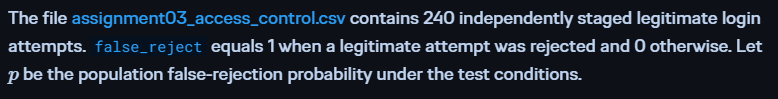
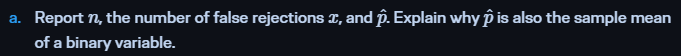

In [14]:
y = access["false_reject"].to_numpy()
n = len(y)
x = int(y.sum())
p_hat = x / n

print(f"n                 = {n}")
print(f"x (false rejects) = {x}")
print(f"p_hat = x / n     = {x}/{n} = {p_hat:.4f}")
print(f"mean of column    = {y.mean():.4f}")

n                 = 240
x (false rejects) = 20
p_hat = x / n     = 20/240 = 0.0833
mean of column    = 0.0833


Each attempt is coded 0 or 1, so adding up the column just counts the 1s: $\sum y_i = x$. Dividing by $n$ gives

$$\bar{y} = \frac{1}{n}\sum_{i=1}^{n} y_i = \frac{x}{n} = \hat{p}.$$

So $\hat{p}$ is a sample mean, and everything from Part I applies to it: $E[\hat{p}] = p$, $SE(\hat{p}) = \sqrt{p(1-p)/n}$, and by the CLT $\hat{p}$ is approximately normal for large $n$. About 8.3% of the 240 staged attempts were falsely rejected.

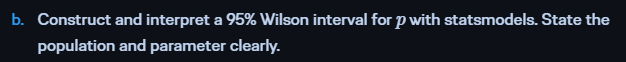

In [15]:
wil_lo, wil_hi = proportion_confint(x, n, alpha=0.05, method="wilson")
print(f"95% Wilson CI = [{wil_lo:.4f}, {wil_hi:.4f}], width = {wil_hi - wil_lo:.4f}")
print(f"distance below p_hat = {p_hat - wil_lo:.4f}, above p_hat = {wil_hi - p_hat:.4f}")

95% Wilson CI = [0.0546, 0.1252], width = 0.0706
distance below p_hat = 0.0287, above p_hat = 0.0419


- **Population:** all legitimate login attempts that could be made under the same staged test conditions.
- **Parameter:** $p$ = the probability that a legitimate attempt is falsely rejected under those conditions.
- **Interval:** we are 95% confident that $p$ is between about 5.5% and 12.5%. The interval is not symmetric around $\hat{p} = 0.083$ and it reaches further up than down, because a proportion near 0 cannot vary as much downward.
- **95% confidence:** if the tests were repeated many times with 240 new attempts and a Wilson interval built each time, about 95% of those intervals would contain the true $p$. This specific interval either contains $p$ or not.

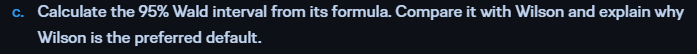

Wald: $\hat{p} \pm z^{*}\sqrt{\hat{p}(1-\hat{p})/n}$

In [16]:
z_star = norm.ppf(0.975)
se_wald = np.sqrt(p_hat * (1 - p_hat) / n)
me_wald = z_star * se_wald
wald_lo, wald_hi = p_hat - me_wald, p_hat + me_wald

print(f"z*            = {z_star:.4f}")
print(f"SE (p_hat)    = sqrt({p_hat:.4f} x {1 - p_hat:.4f} / {n}) = {se_wald:.4f}")
print(f"margin        = {z_star:.4f} x {se_wald:.4f} = {me_wald:.4f}")
print(f"95% Wald CI   = [{wald_lo:.4f}, {wald_hi:.4f}], width = {wald_hi - wald_lo:.4f}")
print(f"95% Wilson CI = [{wil_lo:.4f}, {wil_hi:.4f}], width = {wil_hi - wil_lo:.4f}")

z*            = 1.9600
SE (p_hat)    = sqrt(0.0833 x 0.9167 / 240) = 0.0178
margin        = 1.9600 x 0.0178 = 0.0350
95% Wald CI   = [0.0484, 0.1183], width = 0.0699
95% Wilson CI = [0.0546, 0.1252], width = 0.0706


**Simulation check:** takes 20,000 simulated samples of 240 attempts with p = 0.0833 and counts how often each interval method contains the true p:

In [17]:
rng_cov = np.random.default_rng(2026)
x_sim = rng_cov.binomial(n, p_hat, size=20_000)

for method, name in [("normal", "Wald"), ("wilson", "Wilson")]:
    lo, hi = proportion_confint(x_sim, n, alpha=0.05, method=method)
    print(f"{name:6s} coverage = {np.mean((lo <= p_hat) & (p_hat <= hi)):.4f}")

Wald   coverage = 0.9352
Wilson coverage = 0.9542


- The Wald interval [0.048, 0.118] is symmetric around $\hat{p}$ and sits a bit lower than Wilson [0.055, 0.125]. The widths are almost the same.
- Wald plugs $\hat{p}$ into the SE and assumes $\hat{p}$ is symmetric and normal. When $p$ is close to 0 or 1 (or $n$ is small) that is not true, so Wald's real coverage drops below 95%. In the simulation it only covered $p$ about 93.5% of the time, while Wilson was close to 95%. Wald can also give limits below 0 or above 1.
- Wilson takes the SE at each candidate value of $p$ instead of at $\hat{p}$. This makes it asymmetric near the edges, keeps it inside [0, 1], and gives coverage close to the stated level. That is why it is the default for proportions.

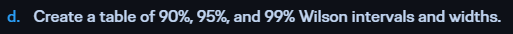

In [18]:
rows = []
for c in [0.90, 0.95, 0.99]:
    lo, hi = proportion_confint(x, n, alpha=1 - c, method="wilson")
    rows.append({
        "confidence": f"{c:.0%}",
        "lower": round(lo, 4),
        "upper": round(hi, 4),
        "width": round(hi - lo, 4),
    })
pd.DataFrame(rows)

,confidence,lower,upper,width
0,90%,0.0584,0.1175,0.0591
1,95%,0.0546,0.1252,0.0706
2,99%,0.0478,0.1412,0.0934


Same trade-off as in Part II: higher confidence gives a wider, less precise interval. All three intervals are above 4.7%, so the false-rejection rate is clearly not close to 0 under these test conditions.

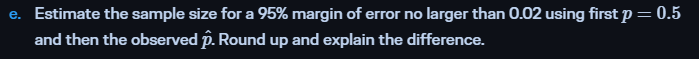

$$n = \left(\frac{z^{*}}{E}\right)^2 p(1-p)$$

In [19]:
E = 0.02
for label, p_plan in [("p = 0.5", 0.5), ("p = p_hat", p_hat)]:
    n_exact = (z_star / E) ** 2 * p_plan * (1 - p_plan)
    print(f"{label:9s}: n = ({z_star:.4f}/{E})^2 x {p_plan:.4f} x {1 - p_plan:.4f} = {n_exact:.2f} -> {int(np.ceil(n_exact))}")

n_upper = (z_star / E) ** 2 * wil_hi * (1 - wil_hi)
print(f"p = Wilson upper {wil_hi:.4f}: n = {n_upper:.2f} -> {int(np.ceil(n_upper))}")

p = 0.5  : n = (1.9600/0.02)^2 x 0.5000 x 0.5000 = 2400.91 -> 2401
p = p_hat: n = (1.9600/0.02)^2 x 0.0833 x 0.9167 = 733.61 -> 734
p = Wilson upper 0.1252: n = 1051.86 -> 1052


- With $p = 0.5$ we need **2,401** attempts; with $\hat{p} = 0.083$ only **734**.
- $p(1-p)$ is largest at $p = 0.5$ (0.25), so 0.5 is the worst case. It guarantees the margin no matter what the true $p$ is, but it is very conservative here.
- Using $\hat{p}$ gives a much smaller $n$ because $p(1-p) = 0.076$ is about a third of 0.25. The risk is that $\hat{p}$ is only an estimate: if the true $p$ were at the Wilson upper limit (0.125), 1,052 attempts would be needed. A practical choice is somewhere between, or planning with the upper limit.

# Part IV AI-use and conclusion

## AI-use

 **Tool**:  GitHub Copilot Chat (agent mode), Claude.

**Used for**: Drafting the code; rephrasing thoughts; recaping theory from the lecture (screen shots from the book and key words were fed in the model)

**Changed / rejected**:  Shortened several AI-drafted comments; changed the calculations, so they are following material from the lectures

**Checked correctness**:  Every code cell was executed in the notebook and its output inspected; Sanity checks via Google and provided course book


## Overall conclusion

Sample size controls how much a statistic varies from sample to sample. In Part I the sample means of the exponential restoration times were always centred at 60 minutes, but their spread (the standard error σ/√n) halved every time n was multiplied by 4. Their shape also moved from strongly right-skewed towards normal, as the CLT predicts. The same √n rule drives interval precision: a smaller standard error gives a narrower confidence interval, while a higher confidence level makes it wider again. Precision is therefore bought with sample size, which is why the planning calculations in II e and III e grow quickly as the required margin gets smaller.

**Sensor calibration:** the mean calibration error is estimated at 0.188 °C, with a 95% t interval of [0.032, 0.345] °C. The whole interval is above 0, so the sensors read slightly too high on average. About 151 sensors would be needed for a margin of ±0.10 °C. Limitation: the interval assumes the 64 sensors are an independent, representative sample. If they all came from one batch or production line, the result may not hold for sensors in general.

**Access control:** the false-rejection rate is estimated at 8.3% (20 of 240), with a 95% Wilson interval of [5.5%, 12.5%]. A margin of ±2 percentage points would need between 734 and 2,401 attempts, depending on the planning value. Limitation: the attempts were staged under test conditions, so the rate may differ for real users, devices and environments.